<a href="https://colab.research.google.com/github/BhumikaSasmal/cryptography-from-scratch/blob/main/02_substitution_cipher.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Substitution Cipher: Implementation and Cryptanalysis

## Objective

A monoalphabetic substitution cipher is a classical encryption technique in which each letter of the plaintext is replaced by a corresponding letter from a substitution alphabet.

Unlike the shift cipher, which moves every letter by the same number of positions, a substitution cipher uses a fixed mapping that can assign a different replacement to each letter.

This notebook explores the mathematical foundation, implementation, testing, and cryptanalysis of a monoalphabetic substitution cipher.

### Learning objectives

- Understand how substitution alphabets and keys work.
- Implement encryption and decryption from scratch using Python.
- Validate substitution keys to ensure that decryption is possible.
- Test normal inputs and edge cases.
- Analyse letter frequencies using statistical techniques.
- Compare the key space with that of the shift cipher.
- Evaluate the algorithm's time complexity and security limitations.

### Scope

This project implements a monoalphabetic substitution cipher for ASCII English letters. Uppercase and lowercase letters are preserved, while digits, spaces, punctuation, and other characters remain unchanged.

The project is intended for education and experimentation. A classical substitution cipher is not suitable for protecting sensitive information.

## 1. Mathematical Foundation

A substitution cipher replaces each plaintext letter with a corresponding ciphertext letter according to a fixed substitution alphabet.

Let:

- \(P\) represent a plaintext letter.
- \(C\) represent its ciphertext equivalent.
- \(S\) represent the substitution mapping.

Encryption applies the mapping:

\[
C=S(P)
\]

Decryption applies the inverse mapping:

\[
P=S^{-1}(C)
\]

### Example substitution

Suppose the standard alphabet is:

`ABCDEFGHIJKLMNOPQRSTUVWXYZ`

And the substitution alphabet is:

`QWERTYUIOPASDFGHJKLZXCVBNM`

Each letter in the standard alphabet maps to the letter in the same position in the substitution alphabet.

For example:

- A maps to Q.
- B maps to W.
- C maps to E.
- H maps to I.
- Z maps to M.

The mapping must be one-to-one: every plaintext letter must map to a unique ciphertext letter.

### Why must the key contain 26 unique letters?

If two plaintext letters mapped to the same ciphertext letter, the receiver would not know which original letter to restore during decryption.

A valid key must therefore contain every letter of the English alphabet exactly once.

### Key space

There are 26 choices for the first substitution, 25 remaining choices for the second, 24 for the third, and so on.

The total number of possible keys is:

\[
26! = 26\times25\times24\times\cdots\times1
\]

\[
26! \approx 4.03\times10^{26}
\]

This is far larger than the 26 possible shifts in a shift cipher. However, a large key space alone does not guarantee security. Substitution ciphers preserve important statistical patterns in the original text.

## 2. Required Libraries

This project uses three standard Python modules and one plotting library.

- `string` provides the standard English alphabet.
- `Counter` counts the occurrences of letters.
- `matplotlib.pyplot` creates visualisations of letter frequencies.

The encryption and decryption algorithms themselves use ordinary Python string operations. No external cryptography library is needed.

In [1]:
import string
from collections import Counter
import matplotlib.pyplot as plt

## 3. Key Validation

The substitution key is a string containing 26 letters. Each position defines the replacement for the corresponding letter in the standard alphabet.

For example, the first character of the key specifies the replacement for A, while the final character specifies the replacement for Z.

The `validate_key()` function checks the following conditions:

1. The key must be a string.
2. It must contain exactly 26 characters.
3. It must contain only ASCII English letters.
4. Each letter must appear exactly once.

The key is converted to uppercase so that the mapping is consistent regardless of how the user enters it.

The function raises an appropriate error when a key is invalid. This prevents ambiguous mappings from being used for encryption or decryption.

In [2]:
ALPHABET = string.ascii_uppercase


def validate_key(key):
    if not isinstance(key, str):
        raise TypeError("Key must be a string.")

    if len(key) != 26:
        raise ValueError("Key must contain exactly 26 letters.")

    if not key.isascii() or not key.isalpha():
        raise ValueError("Key must contain ASCII English letters only.")

    key = key.upper()

    if len(set(key)) != 26:
        raise ValueError("Every letter must appear exactly once.")

    return key

## 4. Encryption Algorithm

The encryption function processes each character in the plaintext individually.

For every ASCII English letter:

1. Convert the letter to uppercase to determine its position.
2. Calculate its zero-based position using `ord()`.
3. Use that position to select a replacement from the substitution key.
4. Convert the replacement to lowercase if the original letter was lowercase.
5. Append the replacement to the result.

Characters that are not ASCII English letters are copied unchanged.

Unlike a shift cipher, the algorithm does not add a fixed number to each letter's position. It directly looks up the replacement letter in the supplied substitution alphabet.

The function validates the key before performing encryption.

In [3]:
def encrypt(text, key):
    key = validate_key(key)

    result = ""

    for char in text:
        if char.isascii() and char.isalpha():
            position = ord(char.upper()) - ord('A')
            encrypted_char = key[position]

            if char.islower():
                encrypted_char = encrypted_char.lower()

            result += encrypted_char
        else:
            result += char

    return result

## 5. Decryption Algorithm

Decryption reverses the substitution mapping.

During encryption, the standard alphabet is mapped to the substitution alphabet. During decryption, the substitution alphabet must be mapped back to the standard alphabet.

The dictionary comprehension constructs this reverse mapping:

- The ciphertext letter becomes the dictionary key.
- The original plaintext letter becomes the corresponding value.

For each character in the ciphertext, the function looks up the original letter in the reverse mapping.

Case is preserved, and non-letter characters remain unchanged.

Because a valid key contains every letter exactly once, each ciphertext letter has exactly one corresponding plaintext letter. This makes the reverse mapping unambiguous.

In [4]:
def decrypt(text, key):
    key = validate_key(key)

    reverse_key = {
        cipher_char: plain_char
        for plain_char, cipher_char in zip(ALPHABET, key)
    }

    result = ""

    for char in text:
        if char.isascii() and char.isalpha():
            decrypted_char = reverse_key[char.upper()]

            if char.islower():
                decrypted_char = decrypted_char.lower()

            result += decrypted_char
        else:
            result += char

    return result

## 6. Demonstration

The example uses a fixed substitution alphabet to make the transformation easy to reproduce and inspect.

The word `Hello` becomes `Itssg`, because each letter is replaced according to the specified key.

The space, comma, exclamation mark, and digits remain unchanged. Decryption restores the original message by applying the inverse mapping.

A correct implementation should satisfy the round-trip property:

\[
D_k(E_k(P))=P
\]

This means that decrypting an encrypted message with the same key must recover the original plaintext.

In [5]:
key = "QWERTYUIOPASDFGHJKLZXCVBNM"
message = "Hello, World! 123"

ciphertext = encrypt(message, key)
plaintext = decrypt(ciphertext, key)

print("Original message:", message)
print("Encrypted message:", ciphertext)
print("Decrypted message:", plaintext)

Original message: Hello, World! 123
Encrypted message: Itssg, Vgksr! 123
Decrypted message: Hello, World! 123


## 7. Basic Testing

The tests verify several important properties of the cipher.

- **Correct mapping:** Selected letters are replaced with their expected equivalents.
- **Case preservation:** Uppercase and lowercase inputs retain their original case.
- **Non-letter preservation:** Numbers, spaces, and punctuation remain unchanged.
- **Empty input:** The algorithm correctly handles an empty string.
- **Round-trip correctness:** Encryption followed by decryption recovers the original message.

Assertions make testing repeatable. If a result differs from the expected value, Python raises an `AssertionError` and identifies the failing test.

In [6]:
key = "QWERTYUIOPASDFGHJKLZXCVBNM"

assert encrypt("ABC", key) == "QWE"
assert decrypt("QWE", key) == "ABC"

assert encrypt("abc", key) == "qwe"
assert encrypt("AbC", key) == "QwE"

assert encrypt("", key) == ""
assert encrypt("123 !@#", key) == "123 !@#"

message = "Cryptography from scratch!"
assert decrypt(encrypt(message, key), key) == message

print("All basic tests passed.")

All basic tests passed.


## 8. Invalid-Key Testing

Key validation is essential because decryption requires a reversible substitution mapping.

The tests include:

- A key that is too short.
- A key that contains fewer than 26 characters.
- A key containing a repeated letter.
- A key containing a digit.
- A key that is not a string.

The algorithm should reject all these invalid keys before encryption begins.

This illustrates a general software engineering principle: validating input early helps prevent errors from spreading through the rest of a program.

In [7]:
valid_key = "QWERTYUIOPASDFGHJKLZXCVBNM"

invalid_keys = [
    "ABC",
    "QWERTYUIOPASDFGHJKLZXCVBN",
    "QWERTYUIOPASDFGHJKLZXCVBNA",
    "QWERTYUIOPASDFGHJKLZXCVBN1",
    123
]

for bad_key in invalid_keys:
    try:
        encrypt("HELLO", bad_key)
    except (TypeError, ValueError):
        pass
    else:
        raise AssertionError(f"Invalid key was accepted: {bad_key}")

assert validate_key(valid_key) == valid_key

print("All key-validation tests passed.")

All key-validation tests passed.


## 9. Visualising the Mapping

The substitution alphabet can be viewed as a lookup table. Each plaintext letter corresponds to the ciphertext letter in the same position.

This mapping is fixed for the entire message. For example, every occurrence of E is replaced by the same ciphertext letter.

This consistency makes the cipher straightforward to implement, but it also creates a weakness: patterns in the original text remain visible after encryption.

In [8]:
key = validate_key("QWERTYUIOPASDFGHJKLZXCVBNM")

print("Plaintext alphabet : ", ALPHABET)
print("Ciphertext alphabet: ", key)

for plain_char, cipher_char in zip(ALPHABET, key):
    print(f"{plain_char} -> {cipher_char}")

Plaintext alphabet :  ABCDEFGHIJKLMNOPQRSTUVWXYZ
Ciphertext alphabet:  QWERTYUIOPASDFGHJKLZXCVBNM
A -> Q
B -> W
C -> E
D -> R
E -> T
F -> Y
G -> U
H -> I
I -> O
J -> P
K -> A
L -> S
M -> D
N -> F
O -> G
P -> H
Q -> J
R -> K
S -> L
T -> Z
U -> X
V -> C
W -> V
X -> B
Y -> N
Z -> M


## 10. Shift Cipher vs. Substitution Cipher

Both algorithms are classical substitution ciphers, but they use different ways to define the mapping.

| Property | Shift cipher | Monoalphabetic substitution |
|---|---|---|
| Key | Integer shift | Permutation of the alphabet |
| Encryption | Arithmetic shift | Character lookup |
| Possible keys | 26 | \(26!\) |
| Mapping | Determined by one shift value | Each letter can have its own replacement |
| Brute-force search | Small and practical | Exhaustive search is impractical |
| Frequency patterns | Preserved | Preserved |
| Known-plaintext weakness | One letter pair can reveal the shift | One letter pair reveals only one mapping |
| Modern security | Insecure | Insecure |

The substitution cipher has a much larger key space than the shift cipher. However, every occurrence of a particular plaintext letter still maps to the same ciphertext letter.

This preserves single-letter frequency patterns and repeated-letter structures, allowing statistical attacks to reduce the number of plausible keys significantly.

## 11. Frequency Analysis

Frequency analysis measures how often each letter occurs in a text.

The `letter_frequency()` function:

1. Extracts ASCII English letters.
2. Converts them to uppercase.
3. Counts the occurrences of each letter using `Counter`.
4. Calculates the percentage of the total letters represented by each character.

Spaces, digits, punctuation, and other characters are excluded.

The function returns all 26 letters, including those that do not appear in the input. These letters receive a frequency of zero.

A substitution cipher changes which letters appear, but it does not change how many times each original letter occurs. Consequently, the frequency distribution is rearranged rather than eliminated.

In [9]:
def letter_frequency(text):
    letters = [
        char.upper()
        for char in text
        if char.isascii() and char.isalpha()
    ]

    counts = Counter(letters)
    total = len(letters)

    if total == 0:
        return {letter: 0.0 for letter in ALPHABET}

    return {
        letter: counts.get(letter, 0) / total * 100
        for letter in ALPHABET
    }


message = (
    "THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG. "
    "THIS EXAMPLE CONTAINS ENGLISH LETTERS FOR FREQUENCY ANALYSIS. "
) * 10

key = "QWERTYUIOPASDFGHJKLZXCVBNM"
ciphertext = encrypt(message, key)

frequencies = letter_frequency(ciphertext)

for letter, percentage in sorted(
    frequencies.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{letter}: {percentage:.2f}%")

T: 11.36%
L: 7.95%
F: 6.82%
G: 6.82%
Z: 6.82%
K: 5.68%
O: 5.68%
Q: 5.68%
S: 5.68%
I: 4.55%
E: 3.41%
N: 3.41%
X: 3.41%
Y: 3.41%
B: 2.27%
D: 2.27%
H: 2.27%
J: 2.27%
U: 2.27%
A: 1.14%
C: 1.14%
M: 1.14%
P: 1.14%
R: 1.14%
V: 1.14%
W: 1.14%


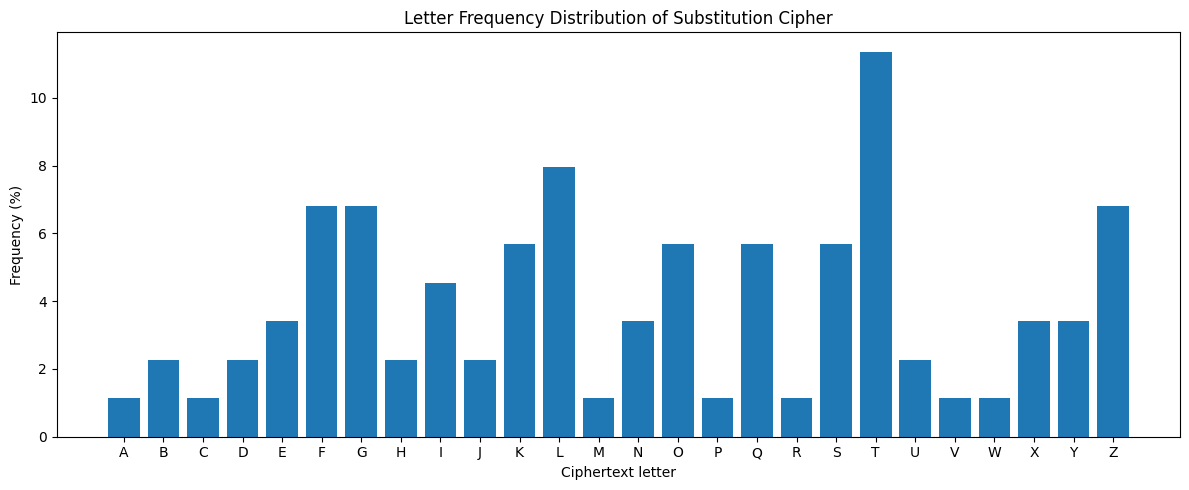

In [10]:
letters = list(frequencies.keys())
percentages = list(frequencies.values())

plt.figure(figsize=(12, 5))
plt.bar(letters, percentages)
plt.xlabel("Ciphertext letter")
plt.ylabel("Frequency (%)")
plt.title("Letter Frequency Distribution of Substitution Cipher")
plt.tight_layout()
plt.show()

## 12. Interpreting the Frequency Chart

The bar chart shows the percentage of the ciphertext represented by each letter.

In ordinary English, E, T, A, O, I, and N tend to appear frequently. After substitution, those letters may appear as completely different ciphertext characters, but their occurrence counts are preserved under the mapping.

For example, if E is replaced by T, every occurrence of E contributes to the frequency of T in the ciphertext.

An attacker can compare the observed ciphertext frequencies with expected English frequencies to develop hypotheses about the substitution key.

The chart is most informative for longer messages. A short message may not contain enough examples to produce a reliable statistical pattern.

## 13. Comparing Plaintext and Ciphertext Distributions

The two distributions contain the same collection of letter counts, but those counts are assigned to different letter labels.

This happens because substitution is a one-to-one mapping. Every occurrence of a plaintext letter becomes one occurrence of its replacement, without changing the number of characters.

The comparison illustrates an important weakness of monoalphabetic substitution: encryption hides the identities of letters but preserves their frequency structure.

Frequency analysis does not automatically recover the full key, but it provides useful clues for further cryptanalysis.

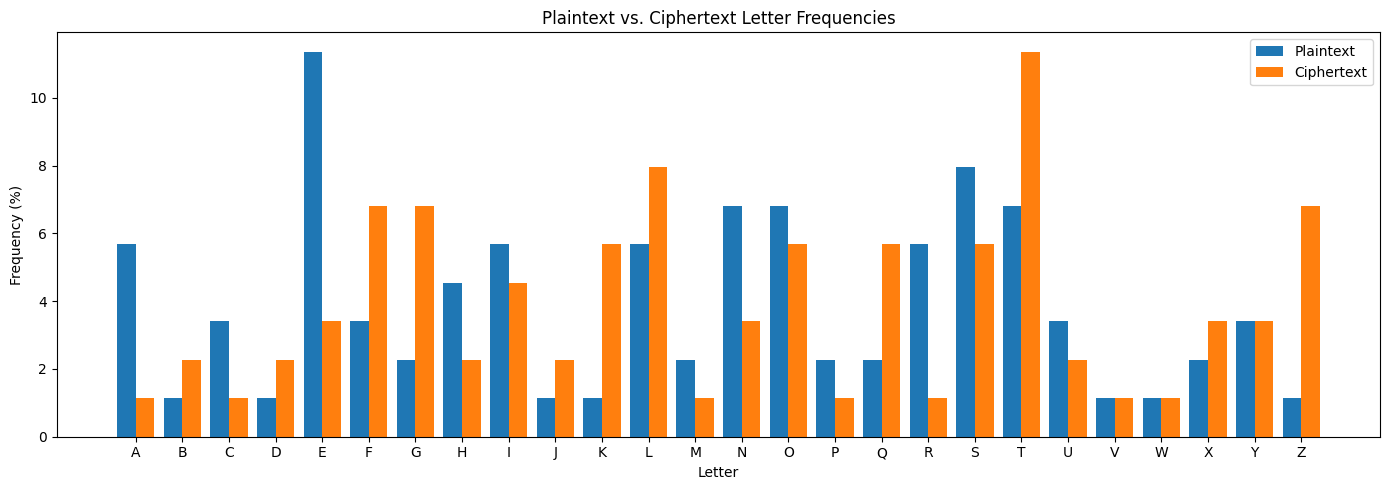

In [11]:
plaintext_frequencies = letter_frequency(message)
ciphertext_frequencies = letter_frequency(ciphertext)

x = list(ALPHABET)
width = 0.4

plt.figure(figsize=(14, 5))

positions = list(range(len(x)))

plt.bar(
    [position - width / 2 for position in positions],
    [plaintext_frequencies[letter] for letter in x],
    width=width,
    label="Plaintext"
)

plt.bar(
    [position + width / 2 for position in positions],
    [ciphertext_frequencies[letter] for letter in x],
    width=width,
    label="Ciphertext"
)

plt.xlabel("Letter")
plt.ylabel("Frequency (%)")
plt.title("Plaintext vs. Ciphertext Letter Frequencies")
plt.xticks(positions, x)
plt.legend()
plt.tight_layout()
plt.show()

## 14. Frequency-Based Mapping Guess

A basic frequency attack ranks ciphertext letters by how often they appear. It then compares this ranking with the usual order of English letter frequencies.

The most frequent ciphertext letter is tentatively mapped to E, the second most frequent to T, and so on.

This is only a heuristic:

- Real text does not always follow the average English distribution.
- Several letters may have similar frequencies.
- Short ciphertexts provide unreliable statistics.
- Letter pairs and word patterns contain additional information that this method ignores.

The resulting mapping should therefore be treated as a hypothesis, not as a recovered key. More advanced attacks can use common digraphs, trigraphs, word patterns, and language scoring to refine the guesses.

In [12]:
ENGLISH_ORDER = "ETAOINSHRDLCUMWFGYPBVKJXQZ"


def frequency_mapping_guess(ciphertext):
    frequencies = letter_frequency(ciphertext)

    ranked_cipher_letters = sorted(
        ALPHABET,
        key=lambda letter: frequencies[letter],
        reverse=True
    )

    return {
        cipher_letter: guessed_plain_letter
        for cipher_letter, guessed_plain_letter
        in zip(ranked_cipher_letters, ENGLISH_ORDER)
    }


guessed_mapping = frequency_mapping_guess(ciphertext)

print("Ciphertext letter -> guessed plaintext letter")

for cipher_letter in sorted(guessed_mapping):
    print(f"{cipher_letter} -> {guessed_mapping[cipher_letter]}")

Ciphertext letter -> guessed plaintext letter
A -> B
B -> W
C -> V
D -> F
E -> L
F -> A
G -> O
H -> G
I -> D
J -> Y
K -> N
L -> T
M -> K
N -> C
O -> S
P -> J
Q -> H
R -> X
S -> R
T -> E
U -> P
V -> Q
W -> Z
X -> U
Y -> M
Z -> I


## 15. Understanding the Key Space

The key space is the set of all possible keys that an algorithm can use.

The shift cipher has only 26 distinct shifts for English letters. A monoalphabetic substitution cipher can permute all 26 letters, producing \(26!\) possible keys.

This is approximately \(4.03\times10^{26}\) possible mappings, which makes exhaustive enumeration of every substitution key impractical.

However, a large key space does not necessarily make an algorithm secure. Frequency analysis exploits patterns that remain visible in the ciphertext, allowing an attacker to narrow the search without testing every key.

This distinction is central to cryptography: security depends not only on the number of keys, but also on the strength of the algorithm against known attacks.


In [13]:
from math import factorial

shift_cipher_keys = 26
substitution_cipher_keys = factorial(26)

print("Shift cipher key space:", shift_cipher_keys)
print("Substitution cipher key space:", substitution_cipher_keys)
print(f"Substitution key space: {substitution_cipher_keys:.3e}")

Shift cipher key space: 26
Substitution cipher key space: 403291461126605635584000000
Substitution key space: 4.033e+26


## 16. Time and Space Complexity

Let \(n\) be the number of characters in the input message.

| Operation | Time complexity | Space complexity |
|---|---|---|
| Key validation | \(O(1)\) | \(O(1)\) |
| Encryption | \(O(n)\) | \(O(n)\) |
| Decryption | \(O(n)\) | \(O(1)\) auxiliary mapping space, excluding output |
| Frequency calculation | \(O(n)\) | \(O(1)\) for a fixed 26-letter alphabet |
| Frequency chart | \(O(1)\) for the fixed set of 26 bars, excluding plotting overhead | \(O(1)\) for the fixed data size |
| Frequency-based mapping guess | \(O(n+26\log26)=O(n)\) | \(O(1)\) for the fixed alphabet |

### Explanation

- **Key validation:** The key always contains 26 positions, so validation takes constant time relative to the message length.
- **Encryption:** Each input character is processed once, producing linear time complexity.
- **Decryption:** Each character is processed once using a reverse dictionary. The dictionary contains only 26 entries.
- **Frequency calculation:** The function scans the text and maintains counts for a fixed alphabet.
- **Frequency-based mapping guess:** Counting frequencies is linear in the message length; sorting the 26 letters is constant-sized work.

The output string requires space proportional to the input length. Auxiliary space describes the additional data structures used by the algorithm, excluding that output.

## 17. Security Analysis

Although a monoalphabetic substitution cipher has a much larger key space than a shift cipher, it is not secure by modern cryptographic standards.

### 1. Preserved letter frequencies

Each plaintext letter always maps to the same ciphertext letter. This preserves single-letter frequency patterns, making statistical analysis possible.

### 2. Repeated-letter patterns

Words with repeated letters retain their repetition structure. For example, a word with two identical letters in the same positions will have the same pattern after encryption.

### 3. Vulnerability to known plaintext

A known plaintext-ciphertext pair reveals the mapping for the corresponding letter. Multiple pairs can reveal more of the key.

### 4. Vulnerability to frequency analysis

An attacker can compare ciphertext letter frequencies with expected language frequencies. Word patterns and common letter combinations can provide further clues.

### 5. No authentication or integrity protection

The cipher does not reliably detect whether an encrypted message has been altered.

### 6. Large key space is not sufficient

The \(26!\) possible mappings make exhaustive search impractical, but statistical attacks can exploit weaknesses without testing all keys.

### Conclusion

A monoalphabetic substitution cipher is valuable for understanding encryption, reversible mappings, and classical cryptanalysis. It should not be used to protect passwords, personal information, or other sensitive data.

Modern applications should use vetted cryptographic algorithms and secure implementations.

## 18. Conclusion

This project implemented a monoalphabetic substitution cipher from scratch using Python.

The notebook covered:

- The mathematical foundation of substitution ciphers.
- Encryption and decryption using forward and reverse mappings.
- Key validation and error handling.
- Testing normal cases, edge cases, and round-trip correctness.
- Comparing substitution and shift ciphers.
- Letter-frequency calculations and visualisation.
- A basic frequency-based mapping heuristic.
- Key-space calculation, complexity analysis, and security limitations.

The project demonstrates that a larger key space does not automatically guarantee security. Although monoalphabetic substitution has far more possible keys than a shift cipher, it preserves statistical properties that can be exploited through cryptanalysis.

This notebook extends the foundation established in the Shift Cipher project and prepares for further exploration of classical encryption techniques and more advanced cryptanalysis methods.